In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## Physical Parameters

In [ ]:
star_radius = 700000 # km
planet_radius = 70000 # km
orbital_period = 5.0 # days
transit_duration = 0.25 # days

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Time observation

### numpy linespace --> using for defining increment automatically calculates exact step size required to fit exactly 2000 points into thayt interval

* Create a smooth curve in any equations or function




In [ ]:
time = np.linspace(0 , 20 , 2000)

### Transit depth

In [ ]:
depth = (planet_radius / star_radius) ** 2

### Construct a simplified transit signal

phase = ((time + orbital_period / 2)
         % orbital_period) - orbital_period / 2

In [ ]:
phase = ((time + orbital_period/ 2) % orbital_period ) - orbital_period / 2

In [ ]:
flux = np.ones_like(time)
flux[np.abs(phase) < transit_duration / 2] -= depth

### Add reproductible observational noise

In [ ]:
rng = np.random.default_rng(42)
noise = rng.normal(0 , 0.001 , size=len(time))
observed_flux = flux + noise

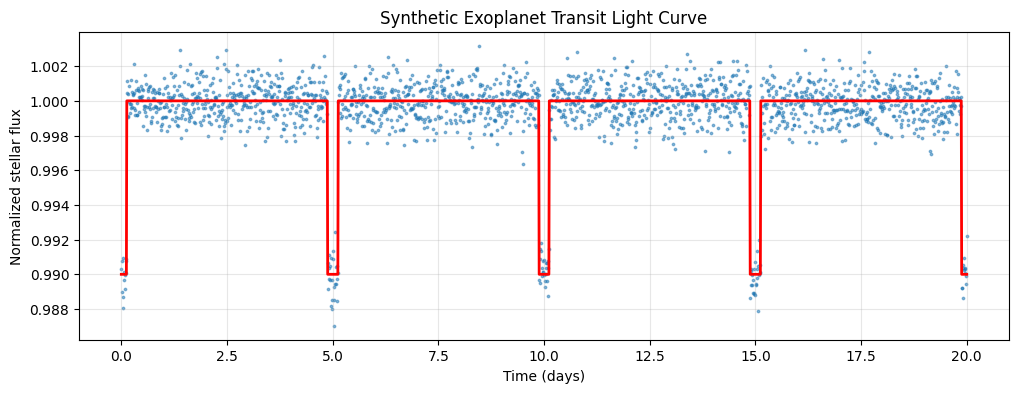

In [ ]:
plt.figure(figsize=(12, 4))
plt.scatter(time, observed_flux, s=3, alpha=0.5)
plt.plot(time, flux, color="red", linewidth=2)
plt.xlabel("Time (days)")
plt.ylabel("Normalized stellar flux")
plt.title("Synthetic Exoplanet Transit Light Curve")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
 !pip -q install lightkurve
!pip install fsspec==2025.12.0

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
  Using cached fsspec-2025.12.0-py3-none-any.whl.metadata (10 kB)
Using cached fsspec-2025.12.0-py3-none-any.whl (201 kB)
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2026.9.0
    Uninstalling fsspec-2026.9.0:
      Successfully uninstalled fsspec-2026.9.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
s3fs 2026.9.0 requires fsspec<2026.9.1,>=2026.9.0, but you have fsspec 2025.12.0 which is incompatible.


In [ ]:
!pip check

ipython 7.34.0 requires jedi, which is not installed.
s3fs 2026.9.0 has requirement fsspec<2026.9.1,>=2026.9.0, but you have fsspec 2025.12.0.


In [ ]:
!pip install "s3fs==2025.12.0" "jedi>=0.16"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.3/14.3 MB 90.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 92.7 MB/s  0:00:00
  Attempting uninstall: wrapt
    Found existing installation: wrapt 2.5.1
    Uninstalling wrapt-2.5.1:
      Successfully uninstalled wrapt-2.5.1
  Attempting uninstall: multidict
    Found existing installation: multidict 7.2.1
    Uninstalling multidict-7.2.1:
      Successfully uninstalled multidict-7.2.1
  Attempting uninstall: botocore
    Found existing installation: botocore 1.43.117
    Uninstalling botocore-1.43.117:
      Successfully uninstalled botocore-1.43.117
  Attempting uninstall: aiobotocore
    Found existing installation: aiobotocore 3.10.0
    Uninstalling aiobotocore-3.10.0:
      Successfully uninstalled aiobotocore-3.10.0
  Attempting uninstall: s3fs
    Found existing installation: s3fs 2026.9.0
    Uninstalling s3fs-2026.9.0:
      Successfully uninstalled s3fs-2026.9.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Data_set")

DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Raw data directory:", RAW_DIR)

Project directory: /content/drive/MyDrive/Data_set
Raw data directory: /content/drive/MyDrive/Data_set/data/raw


In [ ]:
import lightkurve as lk
target = "Kepler-10"

search_result = lk.search_lightcurve(
    target,
    mission="Kepler"
)

print("Available observations:")
print(search_result)

print("Total files:", len(search_result))

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


Available observations:
SearchResult containing 50 data products.

 #       mission      year   author   exptime         target_name          distance
                                         s                                  arcsec 
--- ----------------- ---- ---------- ------- ---------------------------- --------
  0 Kepler Quarter 02 2009     Kepler      60                kplr011904151      0.0
  1 Kepler Quarter 03 2009     Kepler      60                kplr011904151      0.0
  2 Kepler Quarter 03 2009     Kepler      60                kplr011904151      0.0
  3 Kepler Quarter 03 2009     Kepler      60                kplr011904151      0.0
  4 Kepler Quarter 00 2009     Kepler    1800                kplr011904151      0.0
  5 Kepler Quarter 01 2009     Kepler    1800                kplr011904151      0.0
  6 Kepler Quarter 02 2009     Kepler    1800                kplr011904151      0.0
  7 Kepler Quarter 03 2009     Kepler    1800                kplr011904151      0.0
  8 Keple

In [ ]:
lc = search_result[0].download(
    download_dir=str(RAW_DIR)
)

print(lc)

       time             flux      ...   pos_corr1      pos_corr2   
                    electron / s  ...      pix            pix      
------------------ -------------- ... -------------- --------------
200.32408500967722  5.5696000e+05 ... -8.9440849e-03  3.7062202e-02
 200.3247661127025  5.5708588e+05 ... -8.9426376e-03  3.7056953e-02
200.32544721572776  5.5703188e+05 ... -8.9411894e-03  3.7051704e-02
200.32612831898587  5.5684444e+05 ... -8.9397421e-03  3.7046455e-02
 200.3268094220184  5.5680788e+05 ... -8.9382939e-03  3.7041202e-02
 200.3274905250437  5.5690000e+05 ... -8.9368466e-03  3.7035953e-02
200.32817172830255  5.5693525e+05 ... -8.9353984e-03  3.7030704e-02
200.32885283132782  5.5703019e+05 ... -8.9339502e-03  3.7025455e-02
 200.3295339343531  5.5701619e+05 ... -8.9325029e-03  3.7020203e-02
               ...            ... ...            ...            ...
230.29327240424027  5.5692306e+05 ...  1.7958542e-02 -3.4471128e-02
230.29395339702023  5.5673719e+05 ...  1.7963182

In [ ]:
for file in RAW_DIR.iterdir():
    print(file.name, f"{file.stat().st_size / (1024**2):.2f} MB")

mastDownload 0.00 MB


In [ ]:
collection = search_result.download_all(
    download_dir=str(RAW_DIR)
)

print(collection)

LightCurveCollection of 50 objects:
    0: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=2 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    1: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=3 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    2: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=3 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    3: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=3 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    4: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=0 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    5: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=1 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    6: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=2 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    7: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=3 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    8: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=4 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    9: <KeplerLightCurve LABEL="KIC 11904151" QUARTER=5 AUTHOR=Kepler FLUX_ORIGIN=pdcsap_flux>
    10: <Keple

### kepler - 10 : a known planetary system

In [ ]:
# Kepler-10: a known planetary system
search_result = lk.search_lightcurve(
    "Kepler-10",
    mission="Kepler",
    author="Kepler",
    cadence="long"
)
print(search_result)

SearchResult containing 15 data products.

 #       mission      year author exptime  target_name  distance
                                     s                   arcsec 
--- ----------------- ---- ------ ------- ------------- --------
  0 Kepler Quarter 00 2009 Kepler    1800 kplr011904151      0.0
  1 Kepler Quarter 01 2009 Kepler    1800 kplr011904151      0.0
  2 Kepler Quarter 02 2009 Kepler    1800 kplr011904151      0.0
  3 Kepler Quarter 03 2009 Kepler    1800 kplr011904151      0.0
  4 Kepler Quarter 04 2010 Kepler    1800 kplr011904151      0.0
  5 Kepler Quarter 05 2010 Kepler    1800 kplr011904151      0.0
  6 Kepler Quarter 06 2010 Kepler    1800 kplr011904151      0.0
  7 Kepler Quarter 07 2010 Kepler    1800 kplr011904151      0.0
  8 Kepler Quarter 09 2011 Kepler    1800 kplr011904151      0.0
  9 Kepler Quarter 10 2011 Kepler    1800 kplr011904151      0.0
 10 Kepler Quarter 11 2012 Kepler    1800 kplr011904151      0.0
 11 Kepler Quarter 13 2012 Kepler    1800 kplr0

In [ ]:
# Download one available observation segment
lc = search_result[0].download()

In [ ]:
# Remove missing observations
lc = lc.remove_nans()

In [ ]:
# Normalize brightness
lc = lc.normalize()

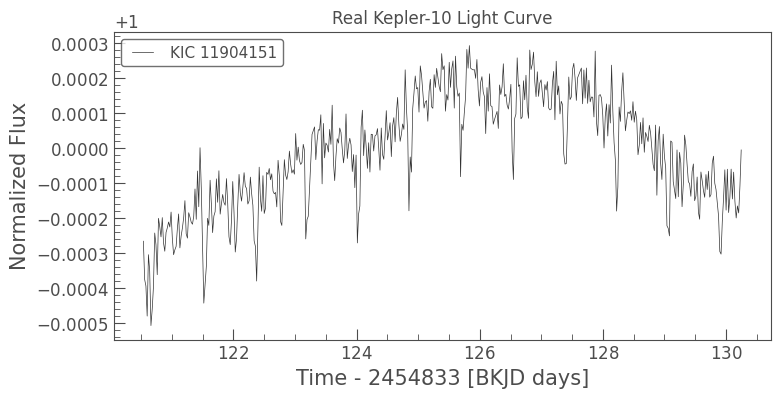

In [ ]:
lc.plot()
plt.title("Real Kepler-10 Light Curve")
plt.show()